# Multiple Linear Regression

Multiple linear regression uses several inputs at once. Each input gets its own weight, and the prediction is the sum. Here we predict **mpg** from the car's weight, horsepower and where it was built.

This notebook goes with the **Multiple Linear Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → turn the category into 0/1 columns → split → fit → read the weights → check the result.

## 1. Load the data

Each row is a car from the late 1970s and early 1980s. We use two numbers (`weight`, `horsepower`) and one category (`origin`: usa, japan or europe).

The data is the [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) data set from the UCI Machine Learning Repository (CC BY 4.0). See `datasets/README.md` for what we changed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/mpg.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,usa
1,15.0,8,350.0,165.0,3693,11.5,70,usa
2,18.0,8,318.0,150.0,3436,11.0,70,usa
3,16.0,8,304.0,150.0,3433,12.0,70,usa
4,17.0,8,302.0,140.0,3449,10.5,70,usa


## 2. Turn the category into numbers

A model needs numbers, so `origin` becomes one 0/1 column per country. This is called **one-hot encoding** (or dummy variables).

Look at the three columns: every car has exactly one `1`, so the columns always add up to 1. That is the **dummy variable trap**: the three columns together repeat the intercept, and the weights stop being unique. The fix is to **drop one column** with `drop_first=True`. The dropped country (europe) becomes the baseline.

In [2]:
dataset = dataset.dropna(subset=['horsepower'])   # a few cars have no horsepower listed
all_three = pd.get_dummies(dataset['origin'])
print((all_three.sum(axis=1) == 1).all(), '<- the three columns always add up to 1')

X = pd.get_dummies(dataset[['weight', 'horsepower', 'origin']], drop_first=True).astype(float)
y = dataset['mpg'].values
X.head()

True <- the three columns always add up to 1


,weight,horsepower,origin_japan,origin_usa
0,3504.0,130.0,0.0,1.0
1,3693.0,165.0,0.0,1.0
2,3436.0,150.0,0.0,1.0
3,3433.0,150.0,0.0,1.0
4,3449.0,140.0,0.0,1.0


## 3. Split into train and test

We keep 25% of the cars back for the test, so the score tells us how the weights carry over to cars the model has never seen.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

294 train, 98 test


## 4. Fit and read the weights

Each weight is the change in predicted mpg for one more unit of that input, with the other inputs held fixed. Weights are only easy to compare when the inputs are on the same scale, so do not read a big weight as a big effect without checking the units.

In [4]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
weights = pd.Series(regressor.coef_, index=X.columns)
print(weights.round(4))
print('intercept:', round(regressor.intercept_, 2))

weight         -0.0053
horsepower     -0.0478
origin_japan    1.3566
origin_usa     -0.9973
dtype: float64
intercept: 44.45


## 5. Check the result

Compare the **test** R² with the one from the simple linear notebook. More inputs usually help, but only the test score can tell you whether they really do.

In [5]:
y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)
print('Train R²:', round(r2_score(y_train, y_pred_train), 3))
print('Test R²: ', round(r2_score(y_test, y_pred_test), 3))
print('Test error on average:', round(mean_absolute_error(y_test, y_pred_test), 2), 'mpg')

Train R²: 0.724
Test R²:  0.702
Test error on average: 3.16 mpg


## Try this

1. Remove `drop_first=True` and fit again. The predictions are almost the same, but look at the weights: they are no longer meaningful.
2. Drop `horsepower` from the inputs. How much does the test R² change?
3. Predict a 3000 lb, 100 hp car from japan. The row must have the same columns as `X`.

## See it: predictions, weights and misses

**Left:** predicted mpg against actual mpg. A perfect model puts every dot on the dashed line. Filled dots are training cars, ringed dots are test cars. **Middle:** the weight of each input (weights use different units, so compare the signs, not the sizes). **Right:** the residuals. **Notice how** the dots follow the dashed line but flatten out at the high-mpg end (the model under-predicts the most efficient cars), and the residuals spread out as the predicted mpg rises.

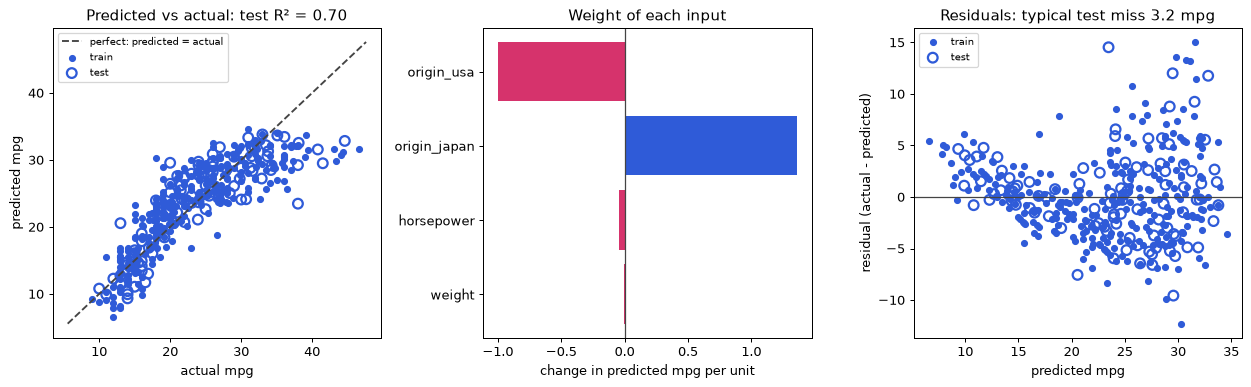

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

p_tr, p_te = regressor.predict(X_train), regressor.predict(X_test)
r2 = r2_score(y_test, p_te)
lo, hi = min(y.min(), p_te.min(), p_tr.min()) - 1, max(y.max(), p_te.max(), p_tr.max()) + 1

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
ax = axes[0]
ax.plot([lo, hi], [lo, hi], '--', color='#444444', label='perfect: predicted = actual')
ax.scatter(y_train, p_tr, color=BLUE, s=22, label='train')
ax.scatter(y_test, p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax.set_xlabel('actual mpg'); ax.set_ylabel('predicted mpg')
ax.set_title(f'Predicted vs actual: test R² = {r2:.2f}')
ax.legend(fontsize=8)

ax = axes[1]
ax.barh(weights.index, weights.values, color=[BLUE if w >= 0 else PINK for w in weights.values])
ax.axvline(0, color='#444444', linewidth=1)
ax.set_title('Weight of each input')
ax.set_xlabel('change in predicted mpg per unit')

ax = axes[2]
ax.axhline(0, color='#444444', linewidth=1)
ax.scatter(p_tr, y_train - p_tr, color=BLUE, s=22, label='train')
ax.scatter(p_te, y_test - p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax.set_xlabel('predicted mpg'); ax.set_ylabel('residual (actual - predicted)')
ax.set_title(f'Residuals: typical test miss {np.abs(y_test - p_te).mean():.1f} mpg')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
